# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Du, Rukaya Selim, Adeline Kwakye

**Date:** 11/9/2026

Df shape: 



(16814, 19)

column information: 

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 

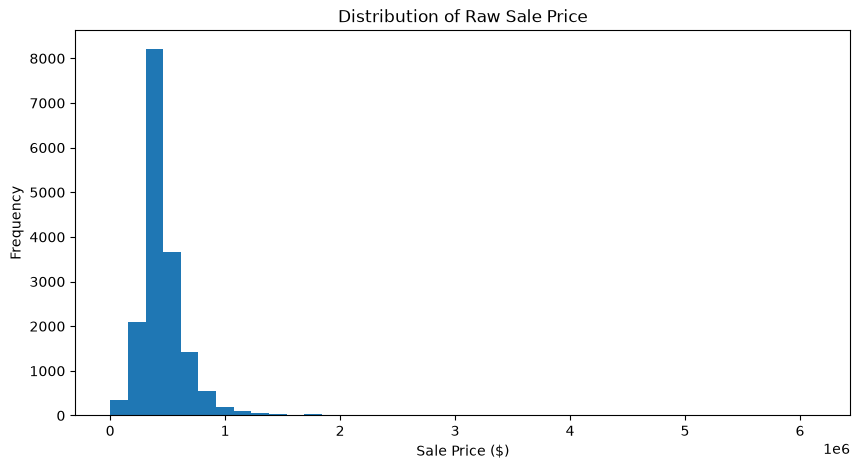

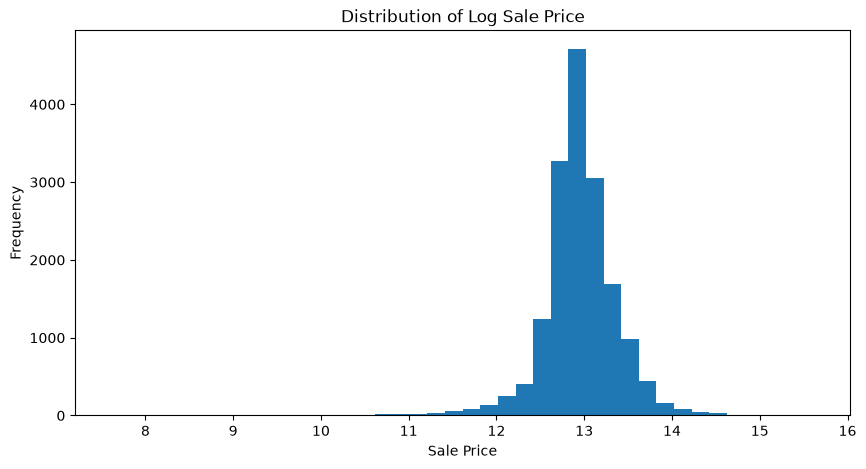

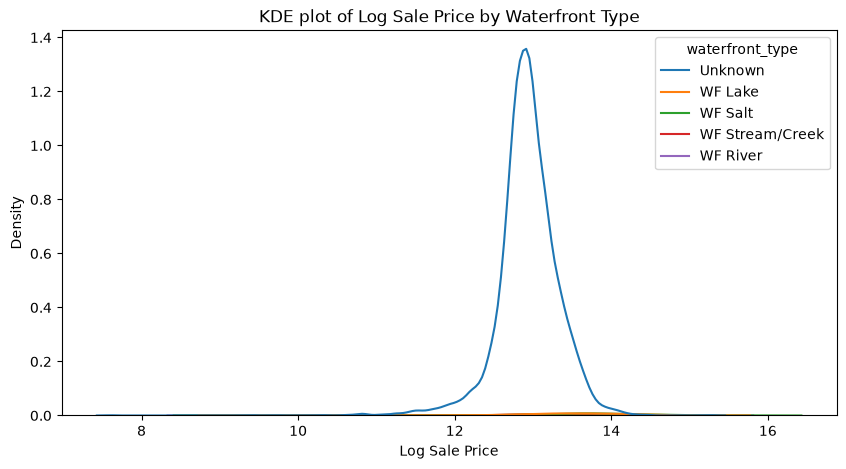

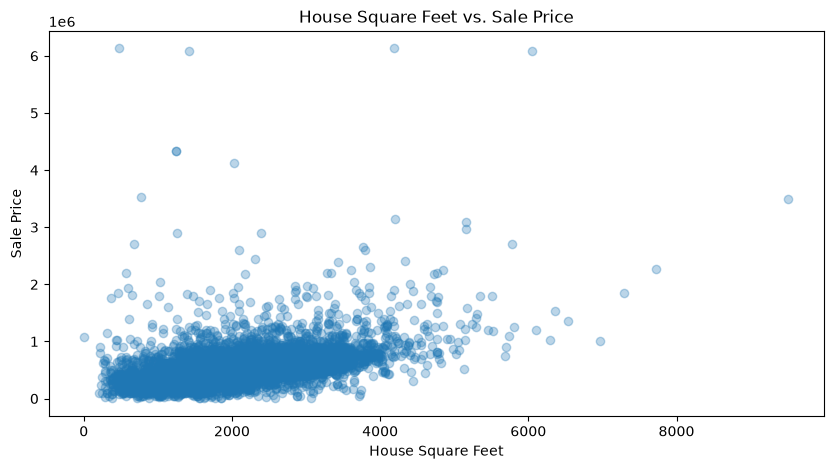

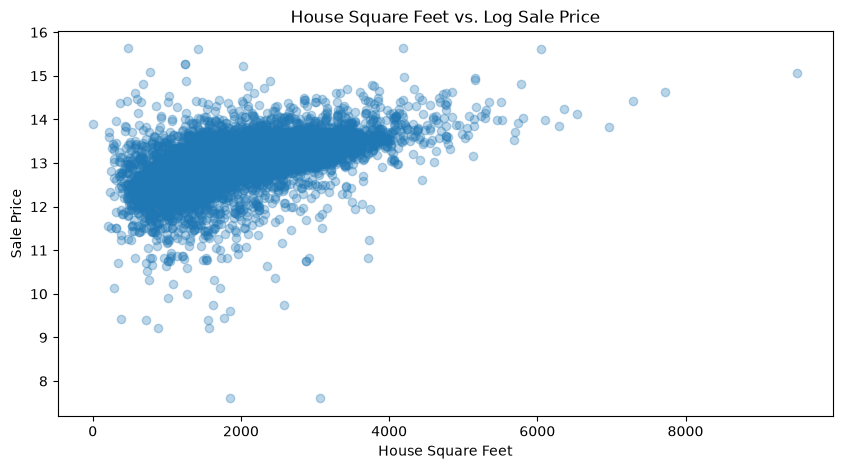

In [ ]:
# Your Phase 1 solution to the problem goes here.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Question 1
df = pd.read_csv("data/pierce_county_house_sales.csv")

#shape
print("Df shape: \n")
display(df.shape)
print("column information: \n")
df.info()
print("duplicated rows count: \n", df.duplicated().sum()) # 46
print("missing values count: \n", df.isna().sum())
print("numerical summary: \n", df.describe())

# drop duplicated
house_df = df.copy()
house_df = house_df.drop_duplicates()
print(house_df.duplicated().sum) # verify that sum is 0

# inspect missing values 
print(house_df['waterfront_type'].value_counts(dropna=False))
print(house_df['view_quality'].value_counts(dropna=False))


print(house_df[['sale_price', 'house_square_feet', 'bedrooms', 'bathrooms']].sort_values(
    by='sale_price'
).head(10))

print(house_df[['sale_price', 'house_square_feet', 'bedrooms', 'bathrooms']].sort_values(
    by='sale_price', ascending=False
).head(10))



# handle missing data 
house_df['waterfront_type'] = house_df['waterfront_type'].fillna('Unknown')

house_df['view_quality'] = house_df['view_quality'].fillna('Unknown')

print(house_df[['waterfront_type', 'view_quality']].isnull().sum())  # verify missing data is 0 


categorical_columns = [
    'hvac_description',
    'exterior',
    'interior',
    'roof_cover',
    'waterfront_type',
    'view_quality'
]

house_df[categorical_columns] = house_df[categorical_columns].fillna('Unknown')

# convert sale_date to be a datetime
house_df['sale_date'] = pd.to_datetime(house_df['sale_date'])
print(house_df['sale_date'].dtype)

# eda visualization
    # histogram for sale price raw data

plt.figure(figsize=(10, 5))
house_df['sale_price'].hist(bins=40, grid=False)
plt.title("Distribution of Raw Sale Price")
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")
plt.show()

# histogram of log-transformed sale price
plt.figure(figsize=(10,5))
house_df['sale_price_log'] = np.log(house_df['sale_price'])
house_df['sale_price_log'].hist(bins=40, grid=False)
plt.title("Distribution of Log Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

# kde plot
plt.figure(figsize=(10, 5))

sns.kdeplot(data=house_df, x='sale_price_log', hue='waterfront_type')
plt.title("KDE plot of Log Sale Price by Waterfront Type")
plt.xlabel("Log Sale Price")
plt.ylabel("Density")
plt.show()

# scatter plot raw version
plt.figure(figsize=(10, 5))
plt.scatter(house_df['house_square_feet'], house_df['sale_price'], alpha=0.3)
plt.title("House Square Feet vs. Sale Price")
plt.xlabel("House Square Feet")
plt.ylabel("Sale Price")
plt.show()

# scatterplot log version
plt.figure(figsize=(10, 5))
plt.scatter(house_df['house_square_feet'], house_df['sale_price_log'], alpha=0.3)
plt.title("House Square Feet vs. Log Sale Price")
plt.xlabel("House Square Feet")
plt.ylabel("Log Sale Price")
plt.show()


In [26]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)


# Question 2: transform categorical variables
house_df.dtypes

categorical_columns = house_df.select_dtypes(include=['object', 'str']).columns
print(categorical_columns) 

# Identify categorical columns
categorical_columns = [
    'hvac_description',
    'exterior',
    'interior',
    'roof_cover',
    'waterfront_type',
    'view_quality',
    'utility_sewer'
]

# One-hot encode categorical variables
house_encoded = pd.get_dummies(
    house_df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Inspect transformed dataset
print("Dataset shape:", house_encoded.shape)
print(house_encoded.dtypes)


Index(['hvac_description', 'exterior', 'interior', 'roof_cover',
       'waterfront_type', 'view_quality', 'utility_sewer'],
      dtype='str')
Dataset shape: (16768, 62)
sale_date                                  datetime64[us]
sale_price                                          int64
house_square_feet                                   int64
attic_finished_square_feet                          int64
basement_square_feet                                int64
attached_garage_square_feet                         int64
detached_garage_square_feet                         int64
fireplaces                                          int64
stories                                             int64
year_built                                          int64
bedrooms                                            int64
bathrooms                                           int64
sale_price_log                                    float64
hvac_description_Electric Baseboard                 int64
hvac_description_

In [29]:
# Question 3 : implement 80/20 train-test split
from sklearn.model_selection import train_test_split
# target variable
y = house_encoded["sale_price"]
# features
X = house_encoded.drop(
    columns=['sale_price','sale_date', 'sale_price_log']
)

# split 80/20
(X_train, X_test, y_train, y_test) = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42
)
print("Training shape:\n")
print("X_train: \n", X_train.shape)
print("y_train: \n", y_train.shape)
print("X_test: \n", X_test.shape)
print("y_test: \n", y_test.shape)

print("\nTraining target summary:\n", y_train.describe())

Training shape:

X_train: 
 (13414, 59)
y_train: 
 (13414,)
X_test: 
 (3354, 59)
y_test: 
 (3354,)

Training target summary:
 count    1.341400e+04
mean     4.619475e+05
std      2.395054e+05
min      2.000000e+03
25%      3.475500e+05
50%      4.170000e+05
75%      5.240000e+05
max      6.130000e+06
Name: sale_price, dtype: float64


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]